In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv('/content/ev_market_2026.csv')

num_cols = df.select_dtypes("number").columns.tolist()
cat_cols = ["brand", "variant", "drive_type", "body_type",
            "country_of_origin", "market_segment"]

print(df.shape)
df.head()

(2000, 24)


,brand,model,year,variant,price_usd,battery_capacity_kwh,range_miles,charging_speed_kw,acceleration_0_60_mph,top_speed_mph,...,body_type,cargo_volume_cubic_ft,weight_kg,safety_rating,autopilot_level,country_of_origin,market_segment,annual_sales_units,customer_rating,warranty_years
0,Volkswagen,ID. Buzz,2023,Performance,104880.80,118.7,400.0,234.5,3.04,195.0,...,Truck,54.2,2015.0,4,2,Germany,Luxury,202182,4.00,4
1,Toyota,bZ Compact SUV,2022,Premium,48217.41,58.8,219.0,148.1,5.77,159.0,...,SUV,69.0,1709.0,4,0,Japan,Mid-range,7146,3.56,3
2,GM/Chevrolet,Bolt EV,2024,Premium,49651.12,58.2,225.0,104.9,6.84,148.0,...,Van,77.0,1533.0,4,1,US,Mid-range,16590,3.70,3
3,Kia,Sportage EV,2024,Long Range,38131.56,102.5,349.0,66.5,4.66,176.0,...,SUV,65.8,1935.0,4,2,South Korea,Mid-range,127201,3.81,3
4,Tesla,Model 3,2022,Long Range,144079.87,93.9,314.0,298.5,5.64,165.0,...,SUV,38.3,2229.0,4,2,US,Luxury,196401,3.83,4


#Data overview


In [ ]:
df.shape

(2000, 24)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   brand                  2000 non-null   object 
 1   model                  2000 non-null   object 
 2   year                   2000 non-null   int64  
 3   variant                2000 non-null   object 
 4   price_usd              2000 non-null   float64
 5   battery_capacity_kwh   2000 non-null   float64
 6   range_miles            2000 non-null   float64
 7   charging_speed_kw      2000 non-null   float64
 8   acceleration_0_60_mph  2000 non-null   float64
 9   top_speed_mph          2000 non-null   float64
 10  horsepower             2000 non-null   float64
 11  torque_nm              2000 non-null   float64
 12  drive_type             2000 non-null   object 
 13  seating_capacity       2000 non-null   int64  
 14  body_type              2000 non-null   object 
 15  carg

In [ ]:
df.describe()

,year,price_usd,battery_capacity_kwh,range_miles,charging_speed_kw,acceleration_0_60_mph,top_speed_mph,horsepower,torque_nm,seating_capacity,cargo_volume_cubic_ft,weight_kg,safety_rating,autopilot_level,annual_sales_units,customer_rating,warranty_years
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,2024.028500,78873.907150,74.662800,261.825500,155.206300,5.630635,164.884500,665.744000,601.311500,5.747000,46.105850,1886.164500,4.377000,1.124500,129653.592000,3.572045,4.579000
std,1.410561,35296.621782,20.082879,71.028238,80.982301,1.417733,20.781244,267.124838,238.706686,1.045245,19.850264,383.772906,0.661127,0.919469,105775.154465,0.270398,1.218812
min,2020.000000,16394.330000,40.000000,150.000000,50.000000,2.500000,118.000000,150.000000,200.000000,2.000000,15.000000,1500.000000,3.000000,0.000000,656.000000,3.000000,3.000000
25%,2023.000000,52325.920000,58.475000,204.000000,90.975000,4.620000,148.000000,442.750000,391.750000,5.000000,28.175000,1570.000000,4.000000,0.000000,44296.500000,3.380000,4.000000
50%,2024.000000,73013.015000,75.100000,261.000000,132.100000,5.670000,165.000000,683.000000,615.500000,5.000000,41.250000,1740.500000,4.000000,1.000000,111188.000000,3.560000,4.000000
75%,2025.000000,99780.157500,87.550000,310.000000,217.300000,6.770000,181.000000,939.250000,845.000000,7.000000,64.700000,2149.500000,5.000000,2.000000,202496.750000,3.750000,5.000000
max,2026.000000,269775.200000,119.900000,447.000000,349.900000,8.000000,200.000000,1000.000000,988.000000,7.000000,80.000000,3000.000000,5.000000,3.000000,499717.000000,4.510000,8.000000


##Cleaning up columns name and text fields

In [ ]:
df_clean = df.copy()

df_clean.columns = (
    df_clean.columns
    .str.strip()
    # remove extra space
    .str.lower()
    .str.replace(" ", "_")
)

cat_cols = df_clean.select_dtypes(include="object").columns

for col in cat_cols:
    df_clean[col] = df_clean[col].str.strip()

df_clean.head()

,brand,model,year,variant,price_usd,battery_capacity_kwh,range_miles,charging_speed_kw,acceleration_0_60_mph,top_speed_mph,...,body_type,cargo_volume_cubic_ft,weight_kg,safety_rating,autopilot_level,country_of_origin,market_segment,annual_sales_units,customer_rating,warranty_years
0,Volkswagen,ID. Buzz,2023,Performance,104880.80,118.7,400.0,234.5,3.04,195.0,...,Truck,54.2,2015.0,4,2,Germany,Luxury,202182,4.00,4
1,Toyota,bZ Compact SUV,2022,Premium,48217.41,58.8,219.0,148.1,5.77,159.0,...,SUV,69.0,1709.0,4,0,Japan,Mid-range,7146,3.56,3
2,GM/Chevrolet,Bolt EV,2024,Premium,49651.12,58.2,225.0,104.9,6.84,148.0,...,Van,77.0,1533.0,4,1,US,Mid-range,16590,3.70,3
3,Kia,Sportage EV,2024,Long Range,38131.56,102.5,349.0,66.5,4.66,176.0,...,SUV,65.8,1935.0,4,2,South Korea,Mid-range,127201,3.81,3
4,Tesla,Model 3,2022,Long Range,144079.87,93.9,314.0,298.5,5.64,165.0,...,SUV,38.3,2229.0,4,2,US,Luxury,196401,3.83,4


.str.strip() removes extra spaces at the start or end (" Price "="Price").
.str.lower() makes everything lowercase ("Price"="price").
.str.replace(" ", "_") swaps spaces for underscores ("battery capacity"= "battery_capacity").

##checking for missing values

In [ ]:
print(df_clean.isnull().sum().sum(), "missing values")
print(df_clean.duplicated().sum(), "duplicate rows")
print(df_clean.dtypes)

0 missing values
0 duplicate rows
brand                     object
model                     object
year                       int64
variant                   object
price_usd                float64
battery_capacity_kwh     float64
range_miles              float64
charging_speed_kw        float64
acceleration_0_60_mph    float64
top_speed_mph            float64
horsepower               float64
torque_nm                float64
drive_type                object
seating_capacity           int64
body_type                 object
cargo_volume_cubic_ft    float64
weight_kg                float64
safety_rating              int64
autopilot_level            int64
country_of_origin         object
market_segment            object
annual_sales_units         int64
customer_rating          float64
warranty_years             int64
dtype: object


In [ ]:
missing_report = df_clean.isna().sum().sort_values(ascending=False)
missing_report = missing_report[missing_report > 0]

if missing_report.empty:
    print("No missing values in any column")
else:
    print(missing_report)

No missing values in any column


#Data quality check: no missing values, no duplicate rows, and all columns have appropriate data types. No imputation or row removal was needed.

#Checking for duplicates

In [ ]:
full_duplicates = df_clean.duplicated().sum()
print(full_duplicates)

logical_key = ["brand", "model", "year", "variant"]
# this particular declare them unique , to check in the data

logical_duplicates = df_clean.duplicated(subset=logical_key, keep=False).sum()
print(logical_duplicates)
# subset=logical_key =compares only those four columns, ignoring price, range, and the rest.

df_clean["is_logical_duplicate"] = df_clean.duplicated(
    subset=logical_key,
    keep=False
)

0
1408


- No exact duplicate rows were found. 1,408 rows share the same brand, model, year, and variant, but they differ in price, specifications, and sales figures, so they were treated as separate records and retained. They are flagged in is_logical_duplicate for reference.

#value range check
## this cell checks the impossile entry like -ve price and the rating of 7 from 1-5 scale.

In [ ]:
checks = {
    "invalid_year": ~df_clean["year"].between(2020, 2026),
    "invalid_price": df_clean["price_usd"] <= 0,
    "invalid_battery": df_clean["battery_capacity_kwh"] <= 0,
    "invalid_range": df_clean["range_miles"] <= 0,
    "invalid_charging_speed": df_clean["charging_speed_kw"] <= 0,
    "invalid_acceleration": df_clean["acceleration_0_60_mph"] <= 0,
    "invalid_horsepower": df_clean["horsepower"] <= 0,
    # This gives True for every row where the price is zero or negative.
    "invalid_safety_rating": ~df_clean["safety_rating"].between(1, 5),
    "invalid_customer_rating": ~df_clean["customer_rating"].between(1, 5),
    "invalid_autopilot_level": ~df_clean["autopilot_level"].between(0, 5),
    "invalid_warranty": ~df_clean["warranty_years"].between(0, 10)
    # flags values outside an allowed range. .between(1, 5) is True when a value
    # is within 1-5, and the ~ flips it, so it is True when the value is outside. It is used for year (2020-2026), safety and customer ratings (1-5), autopilot level (0-5), and warranty (0-10).
}

validation_report = pd.Series({
    name: condition.sum()
    for name, condition in checks.items()
})
# condition.sum() counts the True values,

validation_report

,0
invalid_year,0
invalid_price,0
invalid_battery,0
invalid_range,0
invalid_charging_speed,0
invalid_acceleration,0
invalid_horsepower,0
invalid_safety_rating,0
invalid_customer_rating,0
invalid_autopilot_level,0


Validation checks were applied to year, price, battery capacity, range, charging speed, acceleration, horsepower, ratings, autopilot level and warranty. No invalid or out-of-range values were found, so no rows were removed.

#categorical variable check

In [ ]:
category_cols = [
    "brand",
    "model",
    "variant",
    "drive_type",
    "body_type",
    "country_of_origin",
    "market_segment"
]

for col in category_cols:
    print(f'\n {col}')
    print(df_clean[col].value_counts())
    # CATEGORES WITH THERE TOTAL COUNTS



for col in category_cols:
    df_clean[col] = df_clean[col].astype("category")
    # CHANGE OBJECTS (PLAIN TEXT) TO CATEGORY TYPE (PANDAS )


 brand
brand
Tesla           434
BYD             282
Volkswagen      194
Kia             166
Hyundai         152
BMW             150
GM/Chevrolet    143
Ford            129
Mercedes         96
Audi             77
Toyota           41
Rivian           37
Fisker           25
NIO              23
Porsche          14
Volvo            12
Polestar          9
Xiaomi            8
Lucid             6
Honda             2
Name: count, dtype: int64

 model
model
Model S       93
Cybertruck    90
Model 3       89
Model Y       88
Model X       74
              ..
4              2
e:Ny1          1
ET5            1
e              1
Gravity        1
Name: count, Length: 76, dtype: int64

 variant
variant
Base           420
Long Range     407
Standard       403
Premium        392
Performance    378
Name: count, dtype: int64

 drive_type
drive_type
AWD    754
RWD    678
FWD    568
Name: count, dtype: int64

 body_type
body_type
Truck        427
SUV          364
Hatchback    324
Coupe        303
Sedan    

- 20 brands, 76 models, 5 variants, 3 drive types, 6 body types, 6 countries and 4 market segments

#Outliers
##Q1 is the value below which 25% of the data falls, and Q3 is the 75% point. The IQR (interquartile range) is the spread of the middle 50% of the data.

In [ ]:
num_cols = df_clean.select_dtypes(include= np.number).columns
# This line is meant to collect the numeric columns,

outlier_summary = []

for col in num_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()

    outlier_summary.append({
        "column": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": count
    })

outlier_report = pd.DataFrame(outlier_summary)
outlier_report["outlier_%"] = (outlier_report["outlier_count"] / len(df_clean) * 100).round(2)
outlier_report.sort_values("outlier_count", ascending=False)



,column,lower_bound,upper_bound,outlier_count,outlier_%
16,warranty_years,2.50000,6.50000,162,8.10
14,annual_sales_units,-193003.87500,439797.12500,51,2.55
1,price_usd,-18855.43625,170961.51375,32,1.60
15,customer_rating,2.82500,4.30500,11,0.55
0,year,2020.00000,2028.00000,0,0.00
5,acceleration_0_60_mph,1.39500,9.99500,0,0.00
2,battery_capacity_kwh,14.86250,131.16250,0,0.00
3,range_miles,45.00000,469.00000,0,0.00
4,charging_speed_kw,-98.51250,406.78750,0,0.00
8,torque_nm,-288.12500,1524.87500,0,0.00


- warranty_years: 162 outliers (8.10%)   
- annual_sales_units: 51 outliers (2.55%)   
- price_usd: 32 outliers (1.60%)   
- customer_rating: 11 outliers (0.55%)   

#BOX PLOT FOR PRICES AND SALES

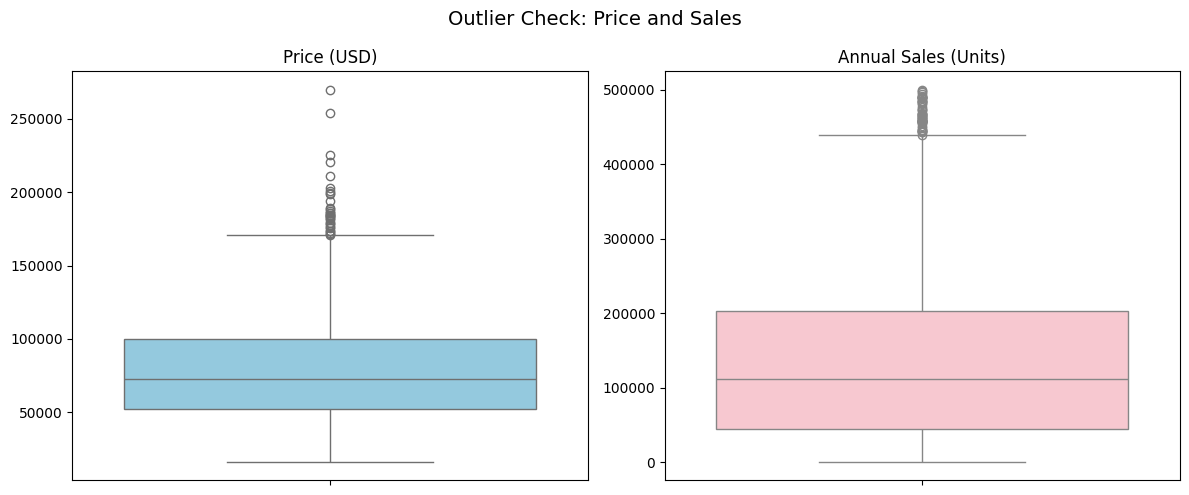

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df_clean["price_usd"], ax=axes[0], color="skyblue")
axes[0].set_title("Price (USD)")
axes[0].set_ylabel("")

sns.boxplot(y=df_clean["annual_sales_units"], ax=axes[1], color="pink")
axes[1].set_title("Annual Sales (Units)")
axes[1].set_ylabel("")

plt.suptitle("Outlier Check: Price and Sales", fontsize=14)
plt.tight_layout()
plt.show()

Outliers were identified using the IQR method. Flagged values in price, sales, warranty and customer rating are legitimate (luxury models, top-selling models, longer warranties) and are not data errors, so no rows were removed or capped.

#Feature Engineering (New features)

In [ ]:
df_clean["price_per_mile"] = df_clean["price_usd"] / df_clean["range_miles"]

df_clean["range_per_kwh"] = (
    df_clean["range_miles"] / df_clean["battery_capacity_kwh"]
)

df_clean["power_to_weight"] = (
    df_clean["horsepower"] / df_clean["weight_kg"]
)

df_clean["sales_value_proxy"] = (
    df_clean["price_usd"] * df_clean["annual_sales_units"]
)
df_clean[["price_per_mile", "range_per_kwh",
          "power_to_weight", "sales_value_proxy"]].describe().round(2)

,price_per_mile,range_per_kwh,power_to_weight,sales_value_proxy
count,2000.00,2000.00,2000.00,2.000000e+03
mean,319.61,3.51,0.37,1.011246e+10
std,162.25,0.22,0.16,1.054857e+10
min,63.49,2.77,0.06,2.531441e+07
25%,200.87,3.37,0.24,3.241650e+09
50%,287.28,3.51,0.36,6.589243e+09
75%,407.11,3.65,0.49,1.360548e+10
max,1212.98,4.46,0.67,7.756137e+10


- this add 4 new columns that are price_per_mile(price/range)	range_per_kwh	(range/battery capacity ),power_to_weight(horsepower/weight),	sales_value_proxy(price*annual sales)

#Graphs

##Histogram for price distribution


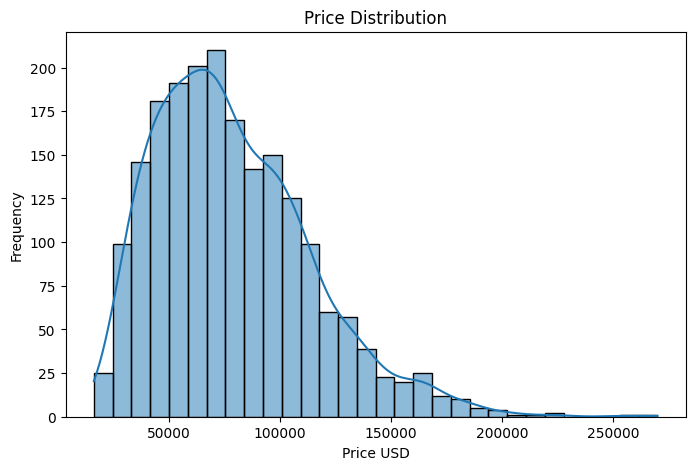

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["price_usd"], bins=30, kde=True)
plt.title("Price Distribution")
plt.xlabel("Price USD")
plt.ylabel("Frequency")
plt.show()

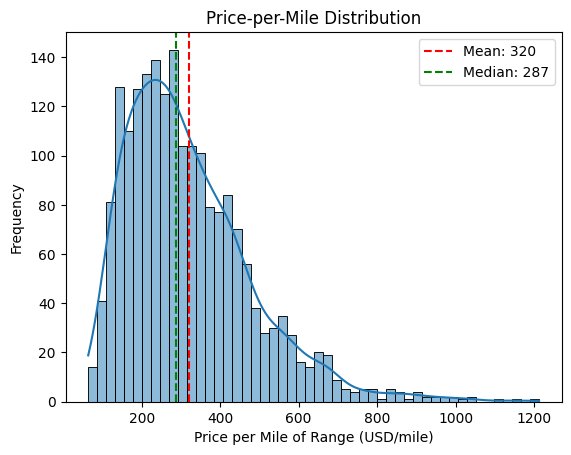

In [ ]:
mean_v = df_clean["price_per_mile"].mean()
median_v = df_clean["price_per_mile"].median()

sns.histplot(df_clean["price_per_mile"], bins=50, kde=True)
# Add the mean and median lines
plt.axvline(mean_v, color="red", linestyle="--", label=f"Mean: {mean_v:.0f}")
plt.axvline(median_v, color="green", linestyle="--", label=f"Median: {median_v:.0f}")
# plt.axvline(x) draws a vertical line at position x.
# color and linestyle="--" make it a dashed red or green line.
# label= gives the line a name for the legend.
# f"Mean: {mean_v:.0f}"=f-string which puts the number into the text, and :.0f= roundss off to a whole number “Mean: 320” and not “Mean: 319.6”.

plt.title("Price-per-Mile Distribution")
plt.xlabel("Price per Mile of Range (USD/mile)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

- price_usd = how much the car costs. price_per_mile is how much you pay for each mile of driving range.

In [ ]:
df_clean.groupby("brand", observed=True)["price_per_mile"].mean().sort_values(ascending=False).head(5)

# GROUPBY = DIVIDES THE TABLE INTO THE GROUP OF BRANDS

,price_per_mile
brand,
Lucid,804.380341
Porsche,576.613722
Mercedes,504.371044
Audi,398.358387
BMW,395.057367


Luxury brands such as Lucid, Porsche, Mercedes, Audi and BMW have the highest average price per mile of range

#Key insights
- Right skewed
- Most cars cost roughly 150 to 450 per mile of range. The tallest bars sit around 200 to 250 per mile
- The mean  is higher than the media which means that small number of high cost vehicles pulls up the averge

#Range distribution

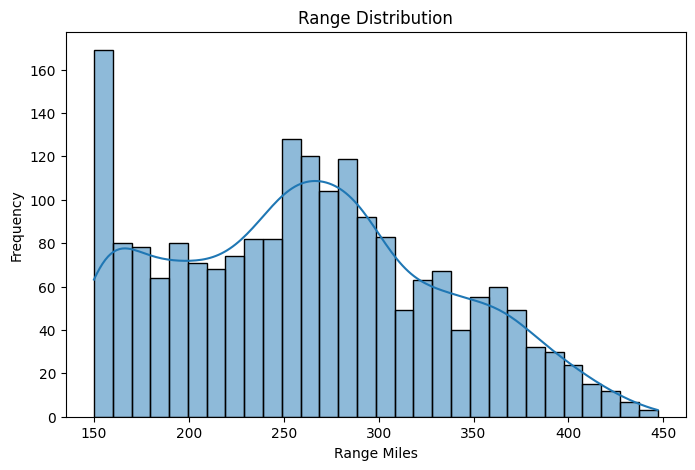

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["range_miles"], bins=30, kde=True)
plt.title("Range Distribution")
plt.xlabel("Range Miles")
plt.ylabel("Frequency")
plt.show()

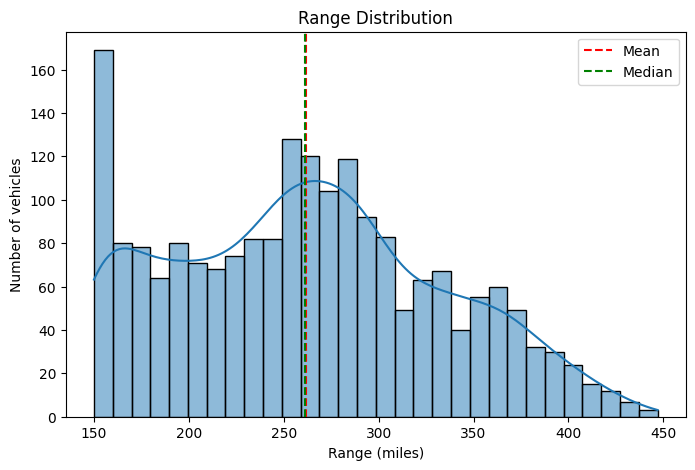

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["range_miles"], bins=30, kde=True)
plt.axvline(df_clean["range_miles"].mean(), color="red", linestyle="--", label="Mean")
plt.axvline(df_clean["range_miles"].median(), color="green", linestyle="--", label="Median")
plt.title("Range Distribution")
plt.xlabel("Range (miles)")
plt.ylabel("Number of vehicles")
plt.legend()
plt.show()

#key insights
- A spike at 150 miles (about 169 cars in the first bar).
-  Symmetric

- mean and median are nearly equal , which shows that this is symmetric

#scatter plot for range and price

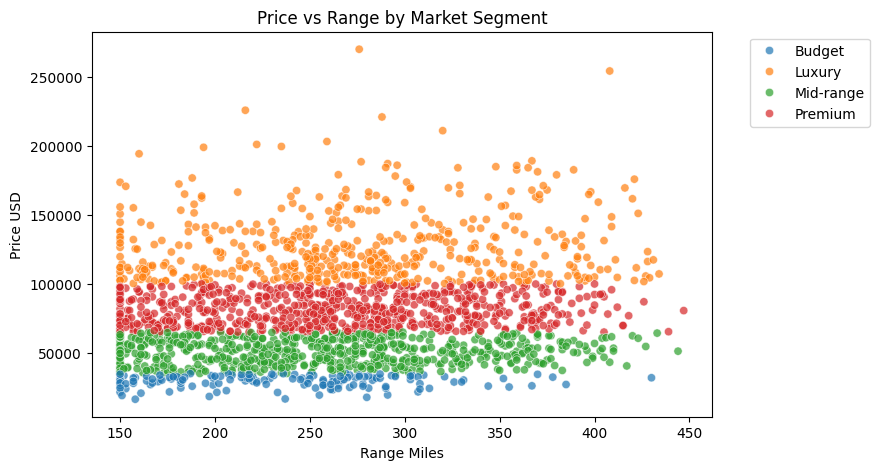

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="range_miles",
    y="price_usd",
    hue="market_segment",
    alpha=0.7
)

plt.title("Price vs Range by Market Segment")
plt.xlabel("Range Miles")
plt.ylabel("Price USD")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

##Multivariate chart
- Luxury has the widest spread and the most extreme points. Its prices run from 100k to about 250k. Budget is much tighter.

#Median price

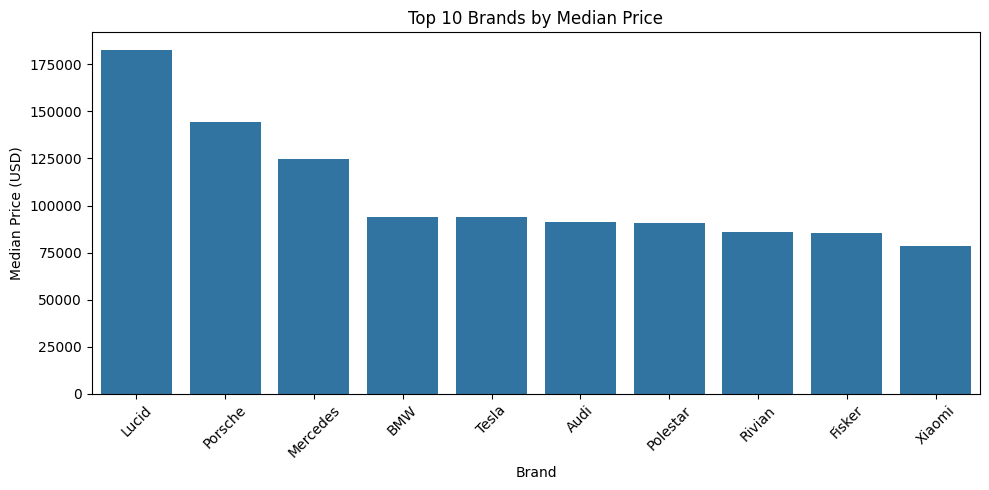

In [ ]:
# brand_price = (
#     df_clean.groupby("brand")["price_usd"]
#     .median()
#     .sort_values(ascending=False)
#     .head(10)
#     .reset_index()
#     # turns the brand names (which are the row labels) into a normal column
# )

# plt.figure(figsize=(10, 5))
# sns.barplot(
#     data=brand_price,
#     x="brand",
#     y="price_usd"
# )
# plt.title("Top 10 Brands by Median Price")
# plt.xlabel("Brand")
# plt.ylabel("Median Price USD")
# plt.xticks(rotation=45)
# plt.show()



brand_price = (
    df_clean.groupby("brand", observed=True)["price_usd"]
    .median()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

brand_price["brand"] = brand_price["brand"].astype(str)
# turns brand back into plain text for plotting, which removes the extra category slots.

plt.figure(figsize=(10, 5))
sns.barplot(data=brand_price, x="brand", y="price_usd",
            order=brand_price["brand"])
plt.title("Top 10 Brands by Median Price")
plt.xlabel("Brand")
plt.ylabel("Median Price (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- Lucid, Porsche and Mercedes have the highest median prices

#Price dist. by Market

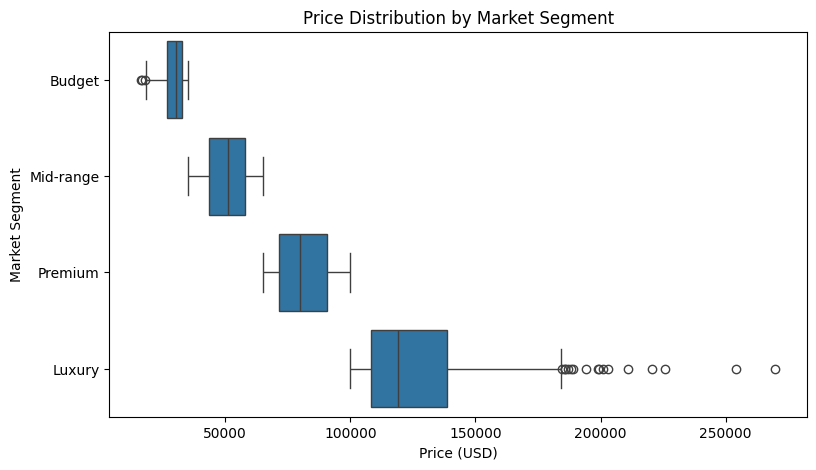

In [ ]:
order = ["Budget", "Mid-range", "Premium", "Luxury"]

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x="price_usd", y="market_segment", order=order)
plt.title("Price Distribution by Market Segment")
plt.xlabel("Price (USD)")
plt.ylabel("Market Segment")
plt.show()

 The box covers the middle 50% of prices (Q1 to Q3), and the line inside is the median.The whiskers extend to the lowest and highest values that aren’t outliers.
The dots are outliers, beyond 1.5 x IQR from the box.
A wider box means more spread in prices.

- Price distributions in the four market segments are clearly separated, because segments are defined by price bands. Variation increases with price: the Budget IQR is tight as compared with  Luxury. Mid-range and Premium have no outliers.

#Battery Capacity - Range

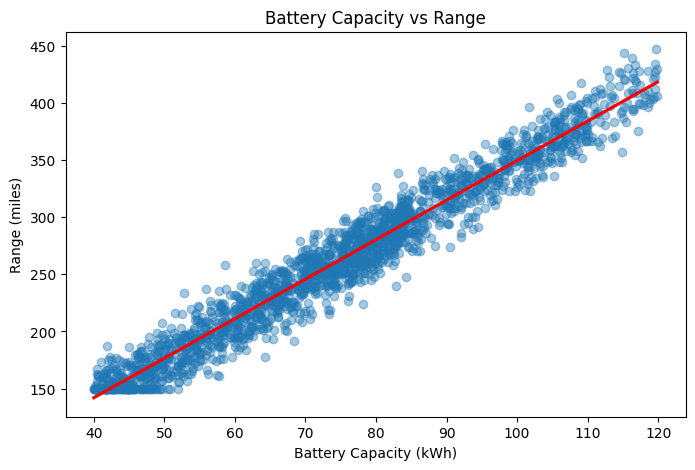

In [ ]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df_clean, x="battery_capacity_kwh", y="range_miles",
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title("Battery Capacity vs Range")
plt.xlabel("Battery Capacity (kWh)")
plt.ylabel("Range (miles)")
plt.show()


- Battery capacity and range show a very strong positive linear relationship

In [ ]:
df_clean["battery_capacity_kwh"].corr(df_clean["range_miles"])

np.float64(0.9778585581959759)

#Power to Weight - Acceleration

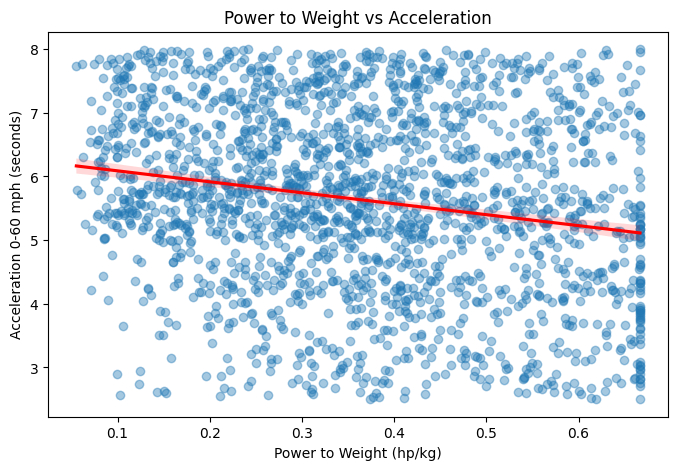

In [ ]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df_clean, x="power_to_weight", y="acceleration_0_60_mph",
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title("Power to Weight vs Acceleration")
plt.xlabel("Power to Weight (hp/kg)")
plt.ylabel("Acceleration 0-60 mph (seconds)")
plt.show()

- scatter_kws={"alpha": 0.4} controls the dots. The _kws stands for “keyword arguments”,

#Correlation Matrix
##Every numeric column is compared with every other numeric column, and the color shows how strongly each pair moves together.

- Bright yellow =strong +ve correlation (close to +1): when one rises, the other rises.
- Dark purple=strong -ve correlation (close to -1): when one rises, the other falls.
- Teal or green in the middle means about 0, so there is little linear relationship.
- The diagonal is always yellow, because each column is perfectly correlated with itself.
- The chart is symmetrical, so the top-right is a mirror of the bottom-left.

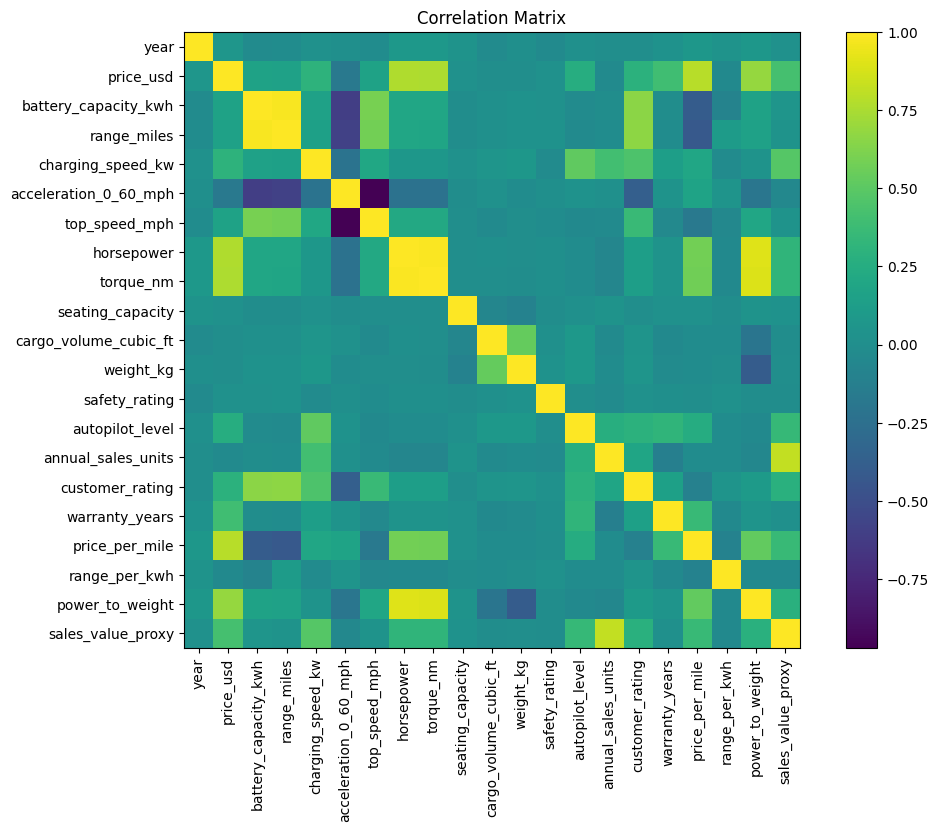

In [ ]:
num_cols = df_clean.select_dtypes(include=np.number).columns

corr = df_clean[num_cols].corr()
# .corr() calculates the correlation for every pair of columns, giving a square table of numbers from -1 to +1.

plt.figure(figsize=(12, 8))
plt.imshow(corr)
# turns that table into a grid of colored squares.
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Matrix")
plt.show()

- The correlation matrix shows very strong relationships between horsepower and torque (0.99)
- battery capacity and range (0.98),
- acceleration and top speed (-0.97), indicating redundant variables.
- Price is most strongly associated with horsepower and torque (0.76).
- Annual sales show only weak correlations with any variable, the highest being charging speed (0.40), while price and range have almost none.

#Correlation Heatmap: Multivariate

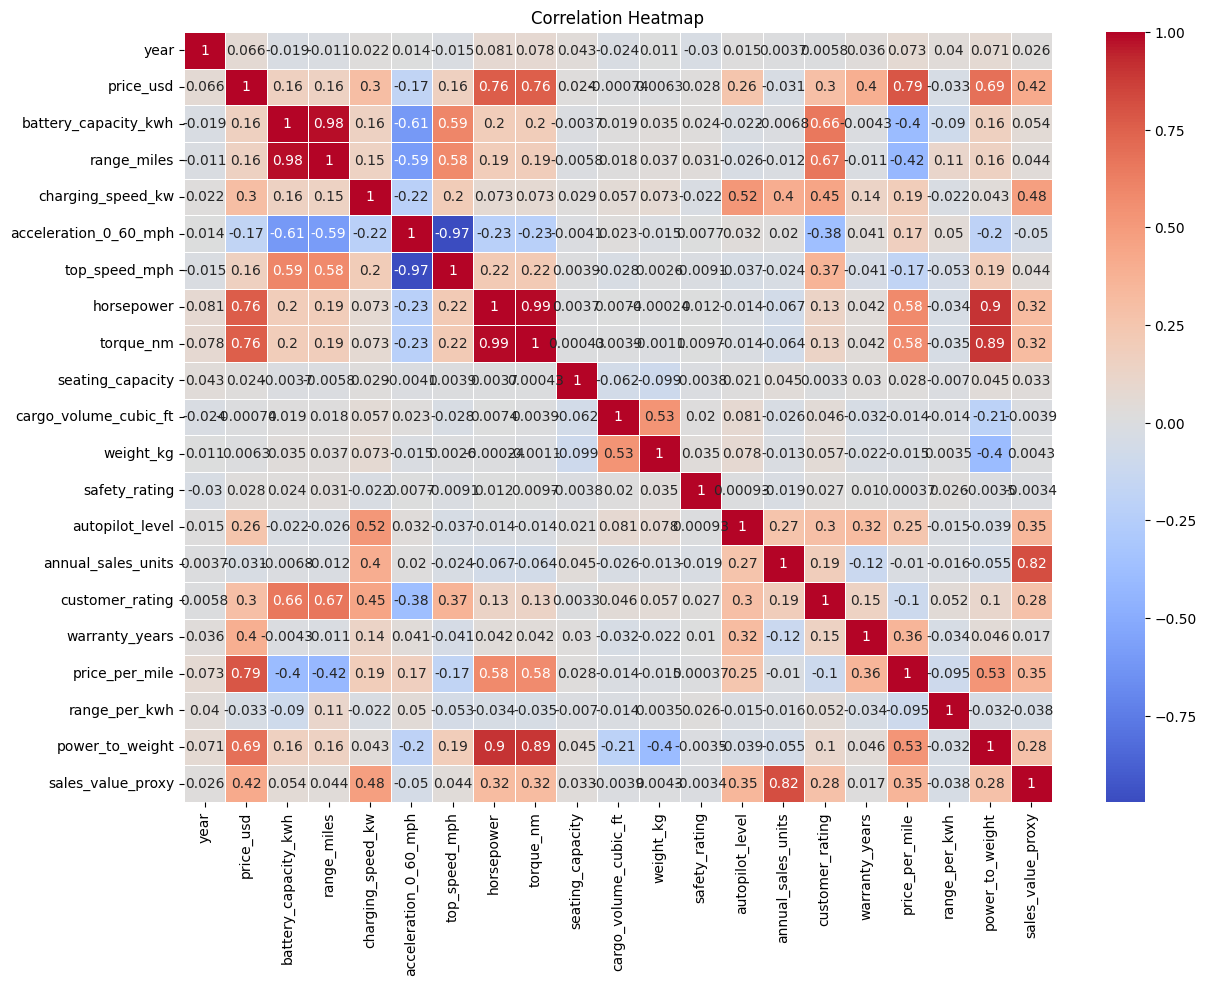

In [ ]:
num_cols = df_clean.select_dtypes(include="number").columns
# Collects the names of all numeric columns

plt.figure(figsize=(14, 10))
sns.heatmap(
    df_clean[num_cols].corr(),
    cmap="coolwarm",
    annot=True,
# numbers not get printed in the squares
    linewidths=0.5
)
plt.title("Correlation Heatmap")
plt.show()

#What does the chart shows
##strong red (+ve correlation )
* horsepower and torque (0.99)
+ battery and capacity range
- price with horsepower and torque (0.76)

##Blue(-ve correlation)
- acceleration and top speed (-0.97)
- acceleration with battery capacity and range (about -0.6)
- price_per_mile with battery and range (about -0.4 to -0.5)

#Brand Distribution
##shows which brand has how many rows

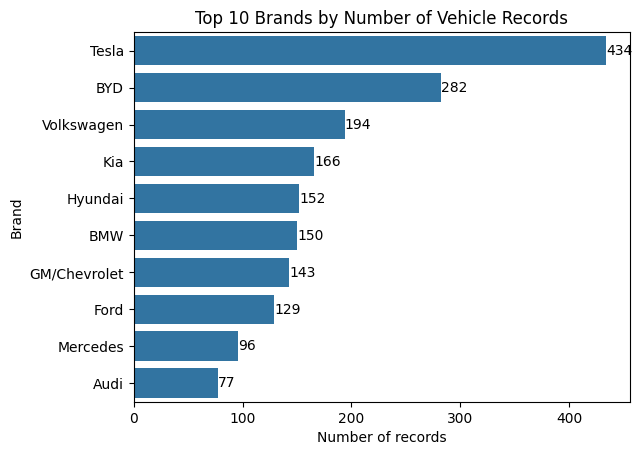

In [ ]:
ax = sns.countplot(data=df_clean, y="brand",
                   order=df_clean["brand"].value_counts().head(10).index)
ax.bar_label(ax.containers[0])
# writes the number at the end of each bar.
plt.title("Top 10 Brands by Number of Vehicle Records")
plt.xlabel("Number of records")
plt.ylabel("Brand")
plt.show()

- Tesla has the most vehicle records (434, about 22% of the dataset), followed by BYD (282) and Volkswagen (194).
- Several brands, including Lucid (6), Xiaomi (8), Polestar (9) and Honda (2), have very few records, so statistics for those brands should be treated with caution


#Vehicle Count by Market Segment
##This bar chart shows how many vehicle records fall into each market segment

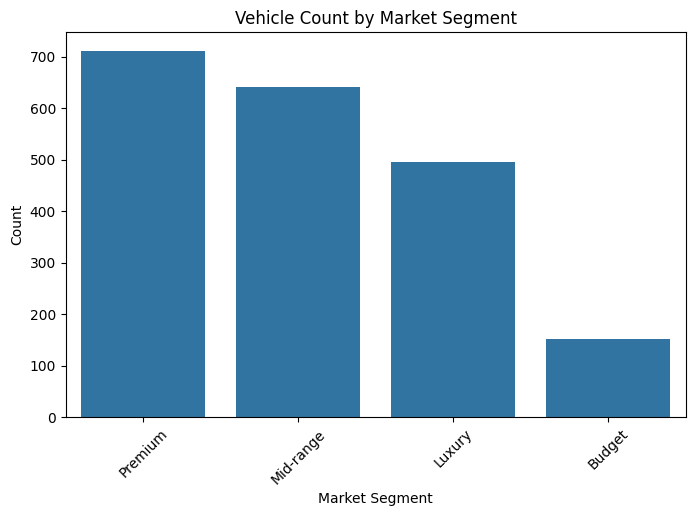

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df_clean,
    x="market_segment",
    order=df_clean["market_segment"].value_counts().index
)
plt.title("Vehicle Count by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

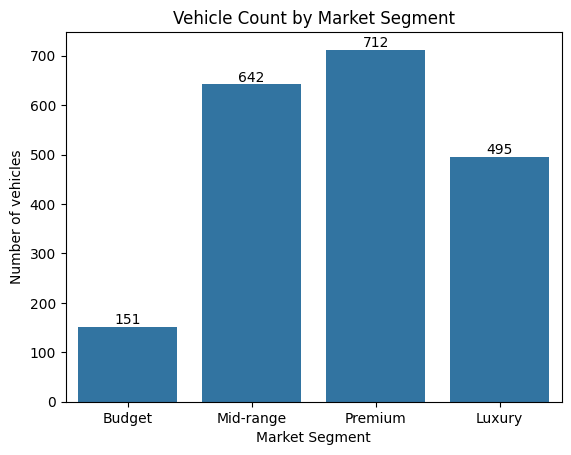

In [ ]:
ax = sns.countplot(data=df_clean, x="market_segment",
                   order=["Budget", "Mid-range", "Premium", "Luxury"])
ax.bar_label(ax.containers[0])
plt.title("Vehicle Count by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Number of vehicles")
plt.show()

- The differnece between both the charts is that the last one contains the number along with the bar so that it is easier for user to interpret the data

In [ ]:
df_clean.groupby("market_segment", observed=True)["annual_sales_units"].agg(["count", "mean", "sum"]).round(0)

,count,mean,sum
market_segment,,,
Budget,151,154658.0,23353407
Luxury,495,133265.0,65966088
Mid-range,642,130031.0,83479890
Premium,712,121500.0,86507799


- Premium (712 records)
- Mid-range (642) are the largest market segments
- Luxury (495).
- Budget is the smallest with 151 records.
- These counts reflect the number of vehicle records, not units sold.

#Average EV Price by Year

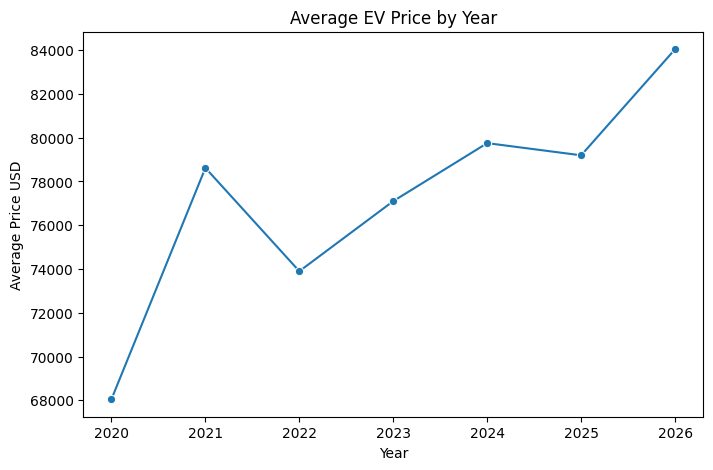

In [ ]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=df_clean,
    x="year",
    y="price_usd",
    estimator="mean",
    # tells seaborn to average all the prices that share the same year
    errorbar=None,
    # switches off the shaded band that seaborn normally draws around the line.
    marker="o"
    # dots
)

plt.title("Average EV Price by Year")
plt.xlabel("Year")
plt.ylabel("Average Price USD")
plt.show()

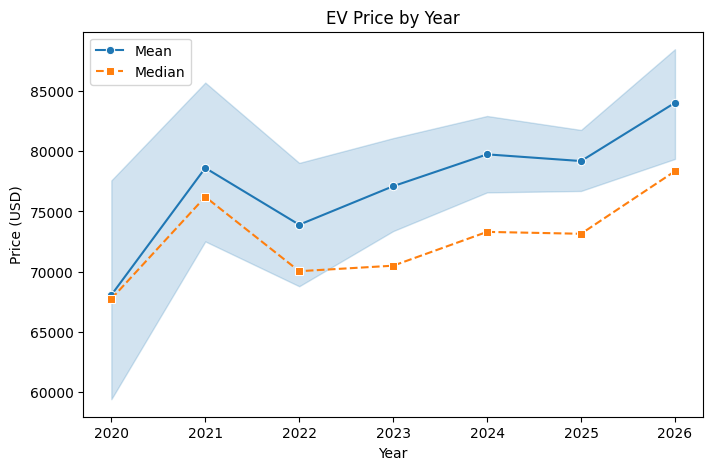

In [ ]:
plt.figure(figsize=(8, 5))
sns.lineplot(data=df_clean, x="year", y="price_usd",
             estimator="mean", marker="o", label="Mean")
sns.lineplot(data=df_clean, x="year", y="price_usd",
             estimator="median", errorbar=None, marker="s",
             linestyle="--", label="Median")
plt.title("EV Price by Year")
plt.xlabel("Year")
plt.ylabel("Price (USD)")
plt.legend()
plt.show()

- The overall direction is upward.
- The path is uneven. There is a sharp jump in 2021, a dip in 2022, a slow rise through 2024, a small dip in 2025, and a jump in 2026.

###The shaded band around a seaborn line plot shows the uncertainty of each point on the line. It answers the question: how much could this average change if I had a different sample of cars?
###Seaborn draws a 95% confidence interval around the mean= where the data possibly lies.

##How to read the blue shaded band
- A narrow band means the average is precise. This happens when there are many records and the values are similar.
- A wide band means the average is uncertain. This happens when there are few records or the values vary a lot.

##In my chart
- the blue part is widest at 2020 that mean here the rocords are lowest
- narrow near 2024-2025 indicating higher records .

#

#Annual Sales Units Distribution

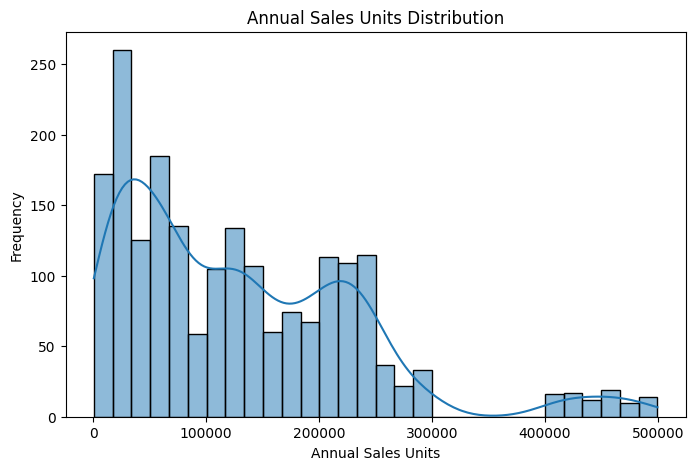

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df_clean["annual_sales_units"], bins=30, kde=True)

plt.title("Annual Sales Units Distribution")
plt.xlabel("Annual Sales Units")
plt.ylabel("Frequency")
plt.show()

In [ ]:
df_clean["price_usd"].skew()

np.float64(0.902435676359446)

- Right-skewed.
- A hard upper limit at 300k, then nothing until 400k. No record has sales between 300,000 and 400,000. The main group ends at about 300k.
- the KDE curve dips to zero between the two groups.
- KDE= kernel destiny estimate

#UNIVARIATE
- Univariate analysis means analyzing one variable at a time.

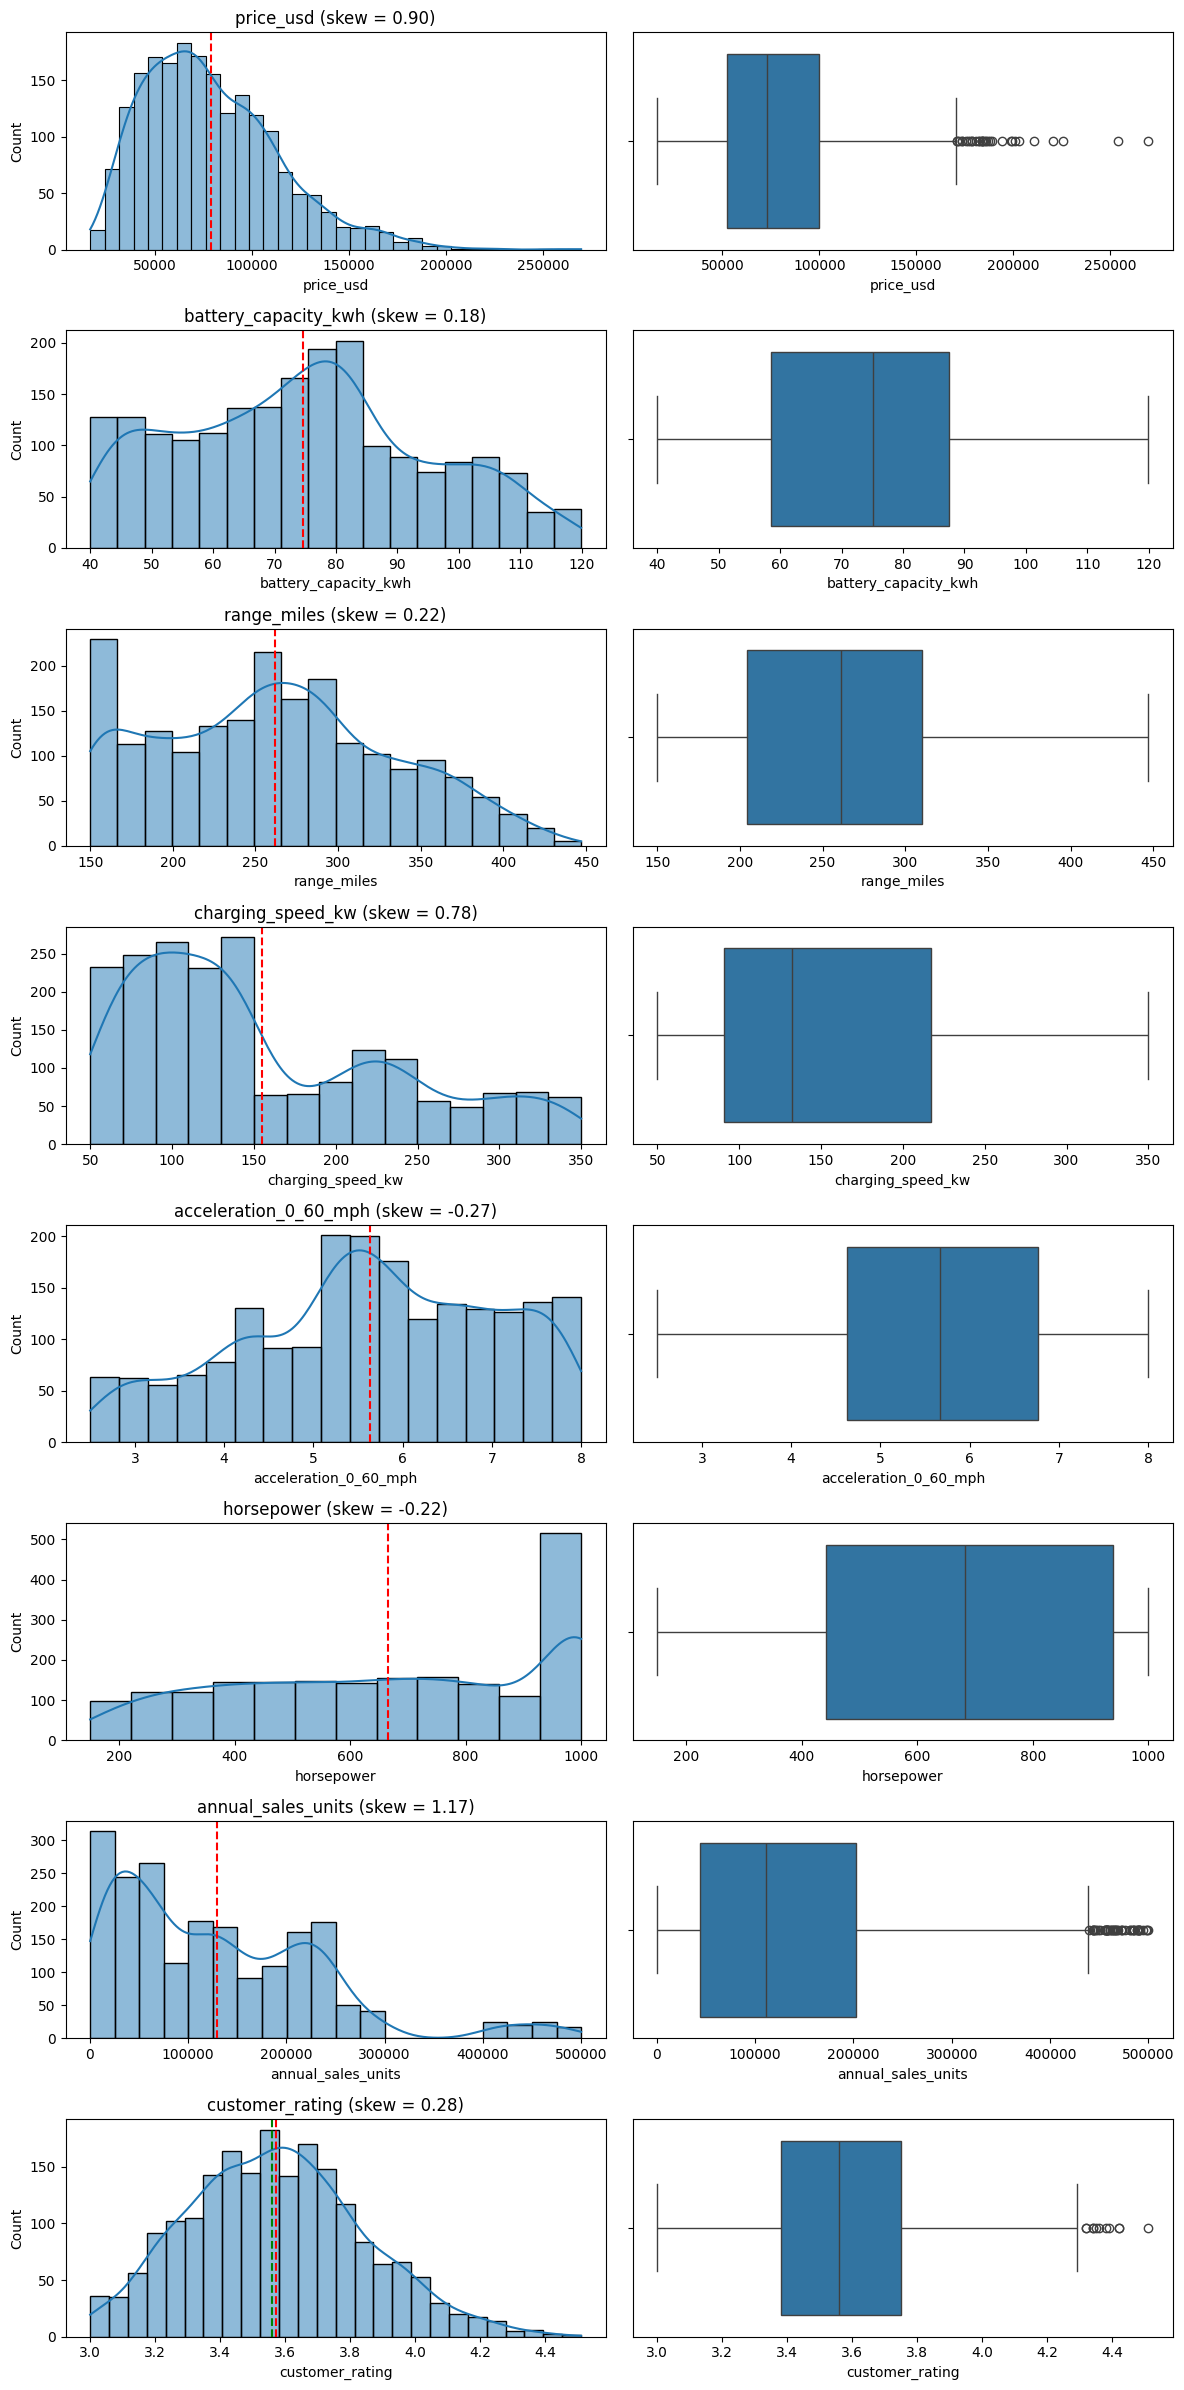

In [ ]:
key_num = ["price_usd", "battery_capacity_kwh", "range_miles",
           "charging_speed_kw", "acceleration_0_60_mph",
           "horsepower", "annual_sales_units", "customer_rating"]

fig, axes = plt.subplots(len(key_num), 2, figsize=(12, 3*len(key_num)))
# Creates a grid of charts with one row per column in key_num (8 rows) and 2 columns. The height scales with the number of rows (3 inches each)

for i, col in enumerate(key_num):
  # enumerate give the row number and column name
    sns.histplot(df[col], kde=True, ax=axes[i, 0])
    # axes[i,0]=mean that histplot will be at index 0
    sns.boxplot(x=df[col], ax=axes[i, 1])
    # and barplot at index 1
    axes[i, 0].set_title(f"{col} (skew = {df[col].skew():.2f})")

    # mean and median for more details
    axes[i, 0].axvline(df[col].mean(), color="red", linestyle="--")
axes[i, 0].axvline(df[col].median(), color="green", linestyle="--")
plt.tight_layout(); plt.show()

- Price and annual sales are right-skewed (0.90 and 1.17)
- Battery capacity, range, acceleration and customer rating are approximately symmetric.
- Outliers were found only in price, sales and customer rating, and were retained as genuine values

#CATEGORICAL COLUMNS = COUNTPLOT

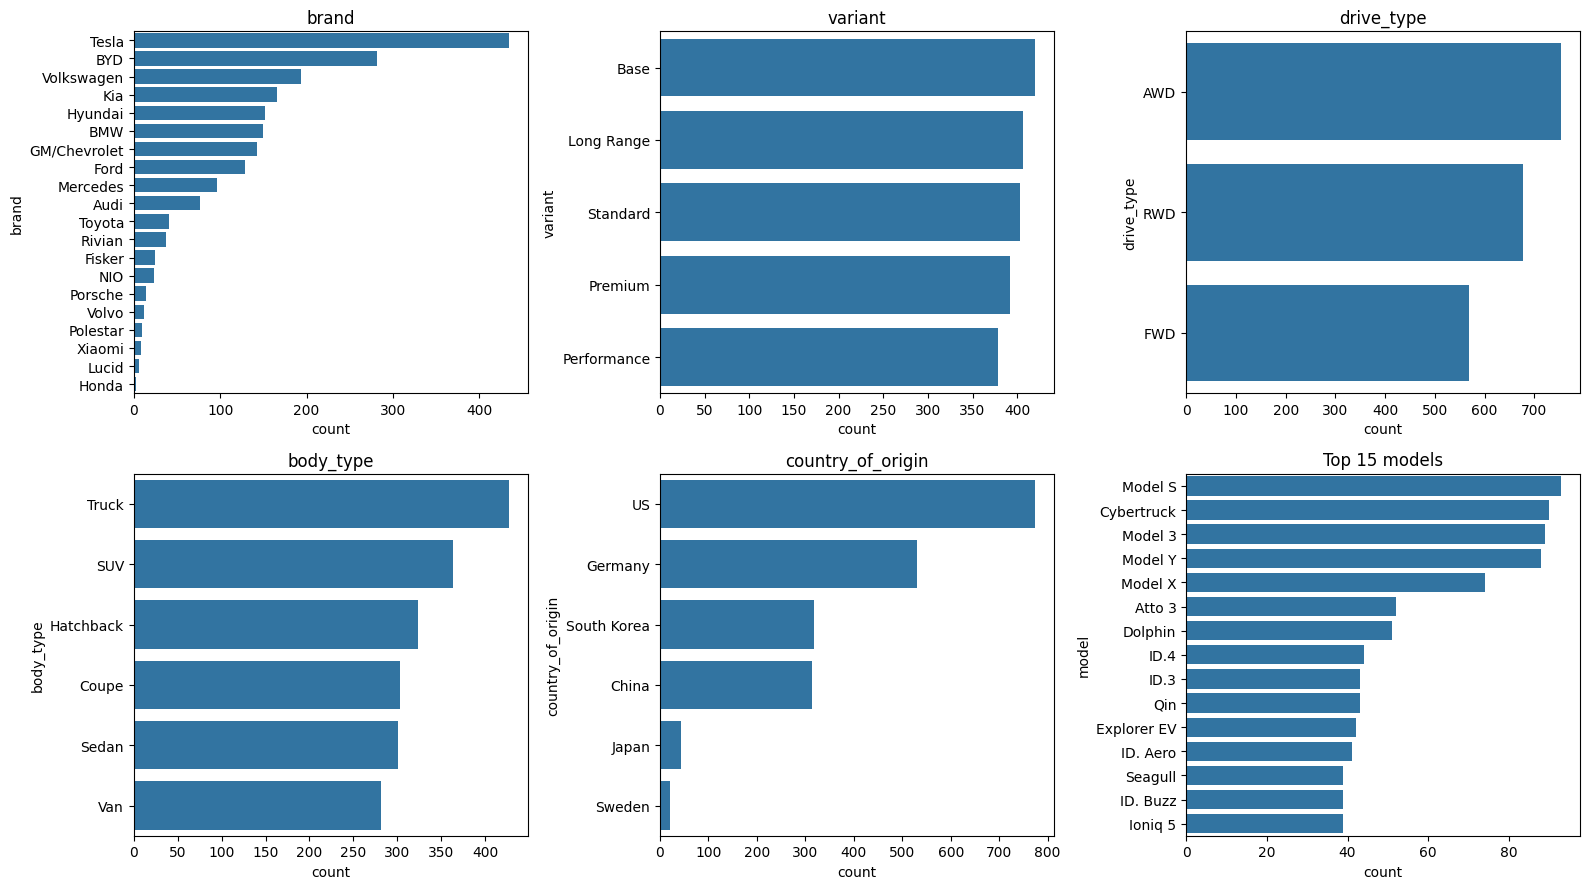

In [ ]:
# AX = individial chart and fig= whole canvas
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
cols = ["brand", "variant", "drive_type", "body_type", "country_of_origin"]


# axes.flat turns the 2x3 grid into a simple list of 6 chart slots
# and zip pairs each slot with one column name from cat_cols
for ax, col in zip(axes.flat, cols):
    order = df_clean[col].value_counts().index

     # value_counts().index gives the category names
    # sorted from most to fewest, and order=order makes the bars follow that order.


    sns.countplot(data=df_clean, y=col, order=order, ax=ax)
    ax.set_title(col)

# 6th panel: top 15 models only
top_models = df_clean["model"].value_counts().head(15).index
sns.countplot(data=df_clean, y="model", order=top_models, ax=axes.flat[5])
axes.flat[5].set_title("Top 15 models")

plt.tight_layout()
plt.show()

- Variant, drive type and body type are close to evenly distributed
- Brand and model are strongly imbalanced
- Country of origin is led by the US  and Germany reflecting the number of brands from each country

#Time - Trend analysis from 2020-2026

In [ ]:
yearly = df_clean.groupby("year").agg(
    records=("year", "size"),
    distinct_models=("model", "nunique"),
    units=("annual_sales_units", "sum"),
    avg_units_per_record=("annual_sales_units", "mean"),
    avg_price=("price_usd", "mean"),
    avg_range=("range_miles", "mean"))
yearly["yoy_growth_%"] = yearly["units"].pct_change() * 100
yearly.round(1)

# agg()= cal summary for each group
# pct_change= cal the %age change from previous row, and*100 gives YoY growth= year-over-year
# first row has no previous row so NaN

,records,distinct_models,units,avg_units_per_record,avg_price,avg_range,yoy_growth_%
year,,,,,,,
2020,39,30,4373954,112152.7,68047.6,268.0,NaN
2021,89,43,11762346,132161.2,78619.5,275.8,168.9
2022,169,58,21426170,126782.1,73897.8,259.3,82.2
2023,304,61,40791903,134183.9,77101.0,257.3,90.4
2024,503,66,64685343,128599.1,79751.6,264.9,58.6
2025,670,70,87603840,130752.0,79194.9,257.7,35.4
2026,226,62,28663628,126830.2,84043.2,268.7,-67.3


- YoY growth slows steadily from +169% in 2021 to +35% in 2025.
- 2026 shows -67%, but it is a partial year (only 226 records), so it is not a real decline.
- Average price and range barely change, apart from a rise to $84k in 2026.

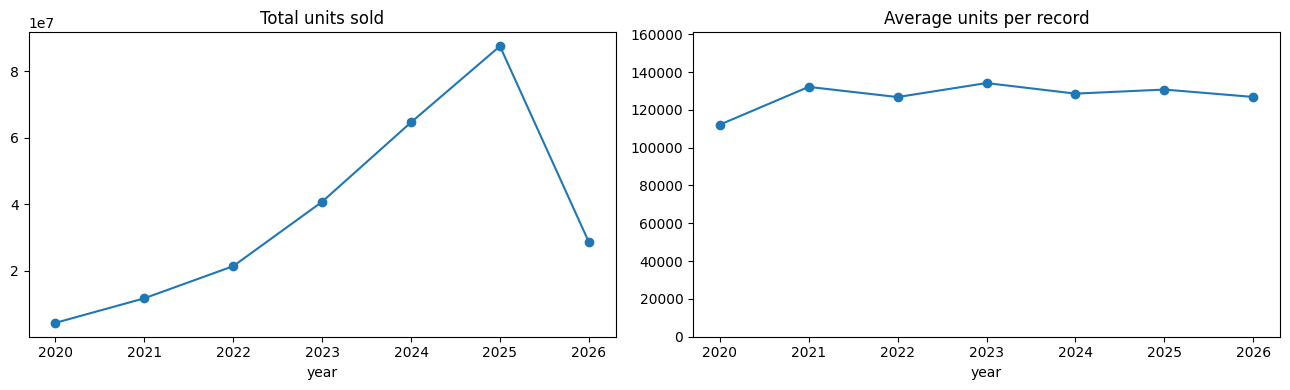

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
yearly["units"].plot(marker="o", ax=ax[0], title="Total units sold")
yearly["avg_units_per_record"].plot(marker="o", ax=ax[1], title="Average units per record")
ax[1].set_ylim(0, yearly["avg_units_per_record"].max() * 1.2)
plt.tight_layout()
plt.show()

#Sale Analysis
##which brands, body types, segments, and countries sell the most.

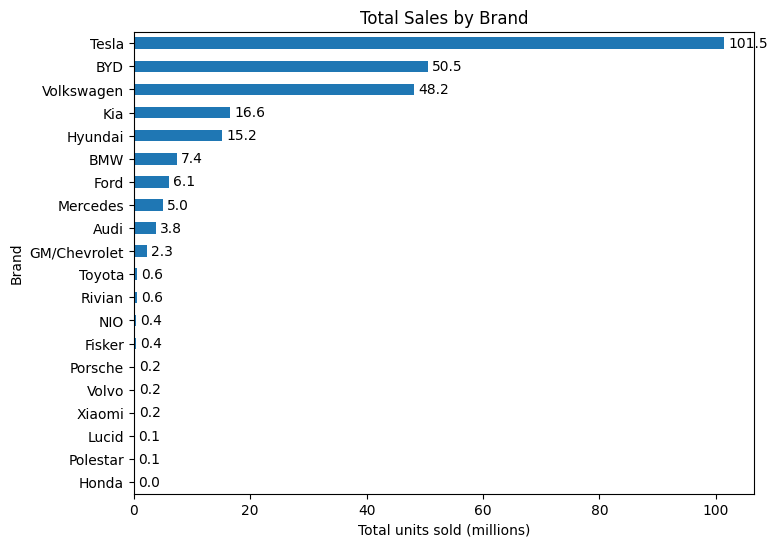

In [ ]:
brand_sales = df_clean.groupby("brand", observed=True)["annual_sales_units"].sum().sort_values()
# .sort_values() sorts from lowest to highest.
#  In a horizontal bar chart the first bar is drawn at the bottom, so the biggest bar ends up at the top.

ax = (brand_sales / 1e6).plot(kind="barh", figsize=(8, 6))
# brand_sales/1e6== divides every total by 1000000(1e6)==axis shows in million ==easy to read
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set_title("Total Sales by Brand")
ax.set_xlabel("Total units sold (millions)")
ax.set_ylabel("Brand")
plt.show()

- Tesla is the longest bar at about 100 million units.
-BYD and Volkswagen come next and are almost equal(near 50M).
- Kia and Hyundai are around 15-17M.
- Everything else is small, and the bottom ten brands are barely visible, because their bars are under 1M next to Tesla’s 100M+.

#Hypothesis testing
##You see a difference in your data and ask: is this difference real, or just luck?
##Eaxmple
####You flip a coin 10 times and get 6 heads. Is the coin unfair? Probably not, because 6 heads happens by luck all the time.
####Now you flip it 100 times and get 90 heads. Is the coin unfair? Almost certainly yes, because luck rarely does that.
####Hypothesis testing is a way to turn that gut feeling into a number.

## According to my Data
####AWD cars average 82.6k and RWD cars average $79.9k. That’s a 2.7k gap.
####Question: do AWD cars really cost more, or is the gap just luck from which cars happen to be in your data?

##The elimination of randomness by some techniques
- Z test
- T test
- ANOVA
- CHI-Square test

##Types of Hypothesis
- Alternate hypothesis H1:True when H0 is false, rejection of NUll implies the acceptence of H1.
- Null hypothesis H0: an established truth is tried to prove wrong in order to  make the other right .

1. H0 (“nothing is going on”)=no relationship
The boring assumption: AWD and RWD cost the same.

2. H1 (“something is going on”)= relationship b/w varibales
What you suspect: AWD and RWD cost different amounts.

3. p-value (“the luck score”)
- How likely it is to see a gap this big if there were really no difference.
- Big p-value (like 0.16): this gap could easily be luck.
- Small p-value (like 0.001): luck almost never makes a gap this big, so the difference is probably real.

4. The cutoff: 0.05
 - p below 0.05: the difference is real, so reject H0.(no luck )
 - p above 0.05: not enough proof, so fail to reject H0.(luck by chance)

In [ ]:
from scipy import stats

# 1. Split cars into two groups
awd = df_clean[df_clean["drive_type"] == "AWD"]["price_usd"]
rwd = df_clean[df_clean["drive_type"] == "RWD"]["price_usd"]

# 2. Run the test
result = stats.ttest_ind(awd, rwd, equal_var=False)

# 3. Read the p-value
print("p-value:", result.pvalue)

if result.pvalue < 0.05:
    print("Real difference")
else:
    print("Could be luck")

p-value: 0.1609699226311507
Could be luck


- T-test = when 2 groups differ.
- Mann-Whitney U=Same as a t-test (2 groups differ), but data is skewed/non-parametric.
- ANOVA= when 3+ grp differs and data is normally distributed  
- Kruskal-Wallis=Same as ANOVa, but skewed
- Pearson (straight-line) or Spearman (rank-based)=2 numeric columns related
- Chi-square= 2 categorical columns related?

In [ ]:
from scipy import stats
# SciPy’s statistics tools.

# 1. ANOVA: does average price differ across market segments?
groups = [g["price_usd"].values for _, g in df_clean.groupby("market_segment", observed=True)]
print(stats.f_oneway(*groups))
# 4 groups= buget , mid range, premium, luxary
# *groups hands those 4 lists to f_oneway as separate inputs.
# f_oneway asks: “Are the 4 average prices different?”



# 2. Correlation: is charging speed related to sales?
print(stats.pearsonr(df_clean["charging_speed_kw"], df_clean["annual_sales_units"]))
print(stats.spearmanr(df_clean["charging_speed_kw"], df_clean["annual_sales_units"]))
# Give each function two columns and it tells you how strongly they move together, from -1 to +1.
# Pearson looks for a straight-line pattern.
# Spearman works on rankings

# 3. t-test: do AWD and RWD cars differ in price?
awd = df_clean[df_clean["drive_type"] == "AWD"]["price_usd"]
rwd = df_clean[df_clean["drive_type"] == "RWD"]["price_usd"]
print(stats.ttest_ind(awd, rwd, equal_var=False))
# The first two lines filter: keep only the AWD rows (or RWD rows) and take their prices.
# ttest_ind compares the averages of the two groups.
# equal_var=False is the safe setting that doesn’t assume both groups are equally spread out.

# 4. Kruskal-Wallis: does sales differ across market segments?
sales_groups = [g["annual_sales_units"].values for _, g in df_clean.groupby("market_segment", observed=True)]
print(stats.kruskal(*sales_groups))
# Same structure as Test 1, but with sales instead of price
# kruskal instead of f_oneway. Kruskal-Wallis is used because sales are heavily skewed, and it works on ranks.

# 5. Mann-Whitney: do SUVs sell differently from other body types?
suv = df_clean[df_clean["body_type"] == "SUV"]["annual_sales_units"]
other = df_clean[df_clean["body_type"] != "SUV"]["annual_sales_units"]
print(stats.mannwhitneyu(suv, other))
# == "SUV" keeps SUVs. != "SUV" keeps everything that is not an SUV.
# mannwhitneyu=ranks version of the t-test, used here because sales are skewed.

# 6. Chi-square: are body type and market segment related?
ct = pd.crosstab(df_clean["body_type"], df_clean["market_segment"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(chi2, p, dof)
# pd.crosstab builds a count table:
# chi2_contingency checks whether those counts look random or show a pattern.
# print(chi2, p, dof) shows the chi-square number, the p-value, and the degrees of freedom.

F_onewayResult(statistic=np.float64(3071.6577576189657), pvalue=np.float64(0.0))
PearsonRResult(statistic=np.float64(0.4016536878825751), pvalue=np.float64(2.0718766164898001e-78))
SignificanceResult(statistic=np.float64(0.3095879751334993), pvalue=np.float64(1.110609782915169e-45))
TtestResult(statistic=np.float64(1.402547740530294), pvalue=np.float64(0.1609699226311507), df=np.float64(1422.633094763645))
KruskalResult(statistic=np.float64(20.785029855160357), pvalue=np.float64(0.00011667133456558339))
MannwhitneyuResult(statistic=np.float64(250561.5), pvalue=np.float64(2.1841146557813022e-06))
16.19936555543824 0.368926886933935 15


In [ ]:
res = stats.ttest_ind(awd, rwd, equal_var=False)
print(f"t = {res.statistic:.2f}, p = {res.pvalue:.4f}")

t = 1.40, p = 0.1610


In [ ]:
results = pd.DataFrame({
    "Test": ["ANOVA (price by segment)", "Pearson (charging speed vs sales)",
             "Welch t-test (AWD vs RWD price)", "Kruskal-Wallis (sales by segment)",
             "Mann-Whitney (SUV vs others, sales)", "Chi-square (body type vs segment)"],
    "Statistic": [3071.66, 0.402, 1.403, 20.785, 250561.5, 16.199],
    "p-value": ["< 0.001", "< 0.001", "0.161", "0.0001", "< 0.001", "0.369"],
    "Decision": ["Reject H0", "Reject H0", "Fail to reject H0",
                 "Reject H0", "Reject H0", "Fail to reject H0"]
})
results

,Test,Statistic,p-value,Decision
0,ANOVA (price by segment),3071.660,< 0.001,Reject H0
1,Pearson (charging speed vs sales),0.402,< 0.001,Reject H0
2,Welch t-test (AWD vs RWD price),1.403,0.161,Fail to reject H0
3,Kruskal-Wallis (sales by segment),20.785,0.0001,Reject H0
4,"Mann-Whitney (SUV vs others, sales)",250561.500,< 0.001,Reject H0
5,Chi-square (body type vs segment),16.199,0.369,Fail to reject H0


#Train and compare

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

# 1. Target and features (leaky columns removed)
target = "price_usd"
leaky = ["annual_sales_units", "sales_value_proxy", "price_per_mile",
         "market_segment", "model", "is_logical_duplicate"]
X = df_clean.drop(columns=[target] + [c for c in leaky if c in df_clean.columns])
y = df_clean[target]

num_ml = X.select_dtypes("number").columns.tolist()
cat_ml = X.select_dtypes(include=["object", "category"]).columns.tolist()

# 2. Train / test split (80 / 20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Preprocessing: scale numbers, one-hot encode categories
pre = ColumnTransformer([("num", StandardScaler(), num_ml),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), cat_ml)])

# 4. Models to compare
models = {"Baseline (mean)": DummyRegressor(),
          "Linear Regression": LinearRegression(),
          "Ridge": Ridge(alpha=1.0),
          "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
          "Gradient Boosting": GradientBoostingRegressor(random_state=42)}

# 5. Train, cross-validate and evaluate
kf = KFold(5, shuffle=True, random_state=42)
rows, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("model", m)])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2").mean()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append([name, cv_r2, r2_score(y_test, pred),
                 mean_absolute_error(y_test, pred), mean_squared_error(y_test, pred) ** 0.5])
    fitted[name] = pipe

results = pd.DataFrame(rows, columns=["Model", "CV R2", "Test R2", "MAE ($)", "RMSE ($)"]).round(3)
results

,Model,CV R2,Test R2,MAE ($),RMSE ($)
0,Baseline (mean),-0.001,-0.001,27067.274,33784.859
1,Linear Regression,0.901,0.891,8128.787,11133.544
2,Ridge,0.898,0.897,7973.408,10818.506
3,Random Forest,0.925,0.903,5501.225,10499.070
4,Gradient Boosting,0.940,0.938,5256.789,8376.371


#feature importance and actual vs predicted

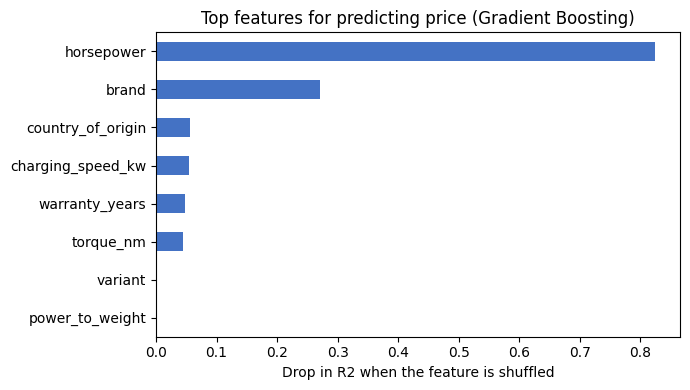

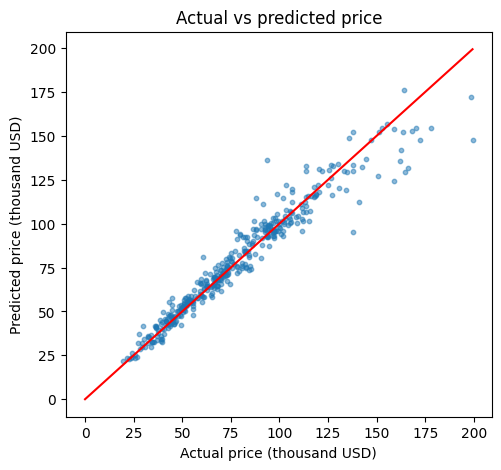

In [ ]:
best = fitted["Gradient Boosting"]
pi = permutation_importance(best, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values().tail(8)
imp.plot(kind="barh", figsize=(7, 4), color="#4472C4")
plt.title("Top features for predicting price (Gradient Boosting)")
plt.xlabel("Drop in R2 when the feature is shuffled")
plt.tight_layout(); plt.show()

pred = best.predict(X_test)
plt.figure(figsize=(5.5, 5))
plt.scatter(y_test / 1000, pred / 1000, s=10, alpha=0.5)
lim = [0, y_test.max() / 1000]
plt.plot(lim, lim, color="red")
plt.xlabel("Actual price (thousand USD)"); plt.ylabel("Predicted price (thousand USD)")
plt.title("Actual vs predicted price"); plt.show()

How to read it:

- R² is the share of price variation the model explains. 0.94 means 94%. The baseline is 0 by definition.
- MAE is the average error in dollars. Gradient Boosting is off by about $5.3k on average, compared with $27k for the baseline.
- The CV and test scores are close (0.940 vs 0.938), so the result is stable and not luck.
- The top features are horsepower (by far) and brand, which fits your earlier correlation finding.

#The second ML part : Predicts customer rating

1. train and compare

In [ ]:
# ---------- ML model 2: predict customer rating ----------

# 1. Target and features (sales columns removed: they are results, not car specs)
target_r = "customer_rating"
leaky_r = ["annual_sales_units", "sales_value_proxy", "model", "is_logical_duplicate"]
Xr = df_clean.drop(columns=[target_r] + [c for c in leaky_r if c in df_clean.columns])
yr = df_clean[target_r]

num_r = Xr.select_dtypes("number").columns.tolist()
cat_r = Xr.select_dtypes(include=["object", "category"]).columns.tolist()

# 2. Split 80 / 20
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

# 3. Preprocessing
pre_r = ColumnTransformer([("num", StandardScaler(), num_r),
                           ("cat", OneHotEncoder(handle_unknown="ignore"), cat_r)])

# 4. Models
models_r = {"Baseline (mean)": DummyRegressor(),
            "Linear Regression": LinearRegression(),
            "Ridge": Ridge(alpha=1.0),
            "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
            "Gradient Boosting": GradientBoostingRegressor(random_state=42)}

# 5. Train, cross-validate, evaluate
rows_r, fitted_r = [], {}
for name, m in models_r.items():
    pipe = Pipeline([("pre", pre_r), ("model", m)])
    cv_r2 = cross_val_score(pipe, Xr_train, yr_train, cv=kf, scoring="r2").mean()
    pipe.fit(Xr_train, yr_train)                      # <- training happens here
    pred = pipe.predict(Xr_test)
    rows_r.append([name, cv_r2, r2_score(yr_test, pred),
                   mean_absolute_error(yr_test, pred), mean_squared_error(yr_test, pred) ** 0.5])
    fitted_r[name] = pipe

results_r = pd.DataFrame(rows_r, columns=["Model", "CV R2", "Test R2", "MAE (stars)", "RMSE (stars)"]).round(3)
results_r

,Model,CV R2,Test R2,MAE (stars),RMSE (stars)
0,Baseline (mean),-0.003,-0.000,0.219,0.276
1,Linear Regression,0.669,0.669,0.127,0.159
2,Ridge,0.669,0.669,0.127,0.159
3,Random Forest,0.632,0.647,0.131,0.164
4,Gradient Boosting,0.642,0.660,0.130,0.161


2. what drives the rating

Best model: Linear Regression


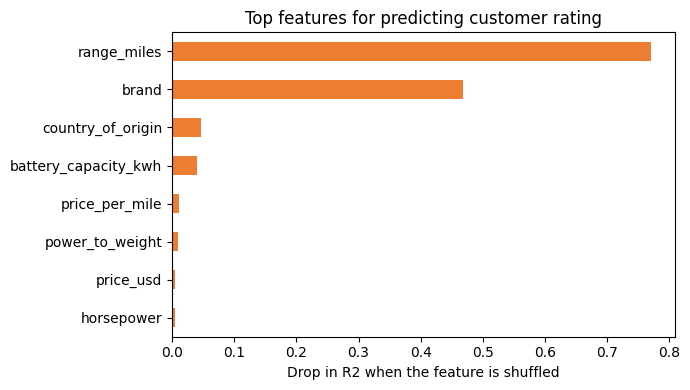

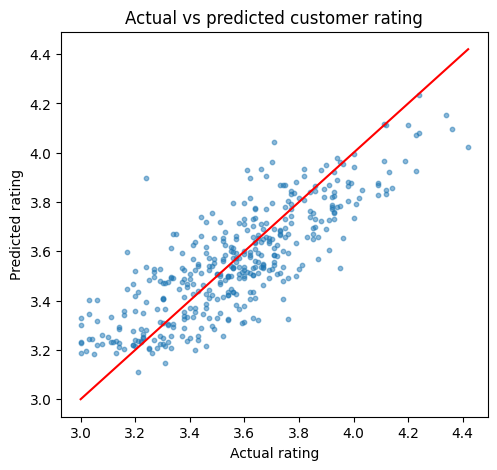

In [ ]:
# 6. Which features drive customer rating?
best_r = max(fitted_r, key=lambda k: results_r.set_index("Model").loc[k, "CV R2"])
print("Best model:", best_r)
pi_r = permutation_importance(fitted_r[best_r], Xr_test, yr_test, n_repeats=5, random_state=42, n_jobs=-1)
imp_r = pd.Series(pi_r.importances_mean, index=Xr.columns).sort_values().tail(8)
imp_r.plot(kind="barh", figsize=(7, 4), color="#ED7D31")
plt.title("Top features for predicting customer rating")
plt.xlabel("Drop in R2 when the feature is shuffled")
plt.tight_layout(); plt.show()

# 7. Actual vs predicted rating
pred_r = fitted_r[best_r].predict(Xr_test)
plt.figure(figsize=(5.5, 5))
plt.scatter(yr_test, pred_r, s=10, alpha=0.5)
lim = [yr_test.min(), yr_test.max()]
plt.plot(lim, lim, color="red")
plt.xlabel("Actual rating"); plt.ylabel("Predicted rating")
plt.title("Actual vs predicted customer rating"); plt.show()

- The models explain about 67% of rating variation. The baseline explains none.
- Average error is about 0.13 stars, compared with 0.22 for the baseline guess. Ratings only vary between 3.0 and 4.5, so this is a good improvement.
- The simple Linear Regression wins here, unlike the price model where Gradient Boosting won. That tells you the rating relationship is mostly a straight line, so a complex model adds nothing. This is a good point to make in your viva: a simpler model is preferred when it performs as well.
- The top features are range (by far) and brand. Battery capacity and country come next. This matches your correlation result: longer-range cars get higher ratings.


#Hyperparameter tuning

In [ ]:
from sklearn.model_selection import GridSearchCV, GroupKFold

# ---- A. Hyperparameter tuning for the price model (Gradient Boosting) ----
param_grid = {"model__n_estimators": [100, 200, 300],
              "model__max_depth": [2, 3, 4],
              "model__learning_rate": [0.05, 0.1]}
gs = GridSearchCV(Pipeline([("pre", pre), ("model", GradientBoostingRegressor(random_state=42))]),
                  param_grid, cv=kf, scoring="r2", n_jobs=-1)
gs.fit(X_train, y_train)
tuned = gs.best_estimator_
pt = tuned.predict(X_test)
print("Best settings:", gs.best_params_)
print(f"Tuned  : test R2 = {r2_score(y_test, pt):.3f}, MAE = {mean_absolute_error(y_test, pt):,.0f}")
pd0 = fitted["Gradient Boosting"].predict(X_test)
print(f"Default: test R2 = {r2_score(y_test, pd0):.3f}, MAE = {mean_absolute_error(y_test, pd0):,.0f}")

# ---- B. Stricter check: the same car model never appears in both train and test ----
groups = df_clean["model"].astype(str)
gcv = cross_val_score(Pipeline([("pre", pre), ("model", GradientBoostingRegressor(random_state=42))]),
                      X, y, groups=groups, cv=GroupKFold(5), scoring="r2")
print("Grouped CV R2 per fold:", gcv.round(3), "| mean:", gcv.mean().round(3))

Best settings: {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 200}
Tuned  : test R2 = 0.948, MAE = 4,764
Default: test R2 = 0.938, MAE = 5,257
Grouped CV R2 per fold: [0.941 0.927 0.949 0.938 0.949] | mean: 0.941


- Tuning improved the model slightly: the average error fell by about $500.
- The grouped score (0.941) is nearly the same as the normal one (0.940), so the model really does generalise to unseen car models, and the repeated rows are not inflating the score.
